
# ARCADE Stenosis — DeepLabV3+ R101 + "Segment → Verify" (new contribution attempt)

**What this notebook does**
1. Trains / reloads the **DeepLabV3+ ResNet101** 5-fold ensemble (same recipe as your last run → same ~0.62 Dice / 0.54 official F1 baseline).
2. Adds **Stage 2 — a lesion verifier** (ResNet18 on image + probability map + candidate mask) that re-scores and filters the candidate lesions. Goal: higher **mAP** and **F1** (your supervisor's advice for an instance-segmentation task).
3. Reports everything your supervisor asked for: **per-image mean Dice**, **pooled (global) Dice**, **TP / FP / FN / TN**, Dice & F1 vs confidence threshold, **mAP50 / mAP50-95**, **official ARCADE F1**, with **95% confidence intervals** and a **paired test of the verifier's gain**.

**Honesty rules built in:** all choices are made on out-of-fold data; the test set is used once; the verifier is claimed as a contribution **only if the paired CI of its gain excludes 0**. If it does not help, the notebook says so.

**How to run (important)**
1. First run with `SMOKE_TEST = True` (~15–20 min): checks that everything runs end-to-end. Numbers are meaningless in this mode.
2. Then `SMOKE_TEST = False`, run all. Time on a T4: **~2.5–3 h** segmenter (skipped if checkpoints are found) **+ ~30–50 min** verifier. On Kaggle use *Save Version → Save & Run All* (GPU on, Internet on).
3. Checkpoints from an earlier run are reused if they are in `run/` or in an attached Kaggle dataset (next cell).


In [1]:
# Do NOT let pip touch torch: --no-deps keeps the preinstalled torch/numpy/opencv exactly as they are.
!pip install -q kagglehub
!pip install -q --no-deps segmentation-models-pytorch
print("Installs complete. If you ever see 'Trying to override a python impl...' -> Run > Restart session, then run from the top (do not re-run this cell).")

Installs complete. If you ever see 'Trying to override a python impl...' -> Run > Restart session, then run from the top (do not re-run this cell).


In [2]:
import os, sys, json, math, copy, random, itertools, shutil, time, warnings, subprocess
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
for _try in range(8):          # smp needs a few small packages; install any that are missing WITHOUT touching torch
    try:
        import segmentation_models_pytorch as smp; break
    except ModuleNotFoundError as e:
        print("missing package:", e.name, "-> installing (no deps)")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--no-deps", e.name.split(".")[0].replace("_", "-")])
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore")
SEED = 42
def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_CUDA = DEVICE.type == "cuda"
torch.backends.cudnn.benchmark = True
ON_KAGGLE = Path("/kaggle/working").exists()
BASE = Path("/kaggle/working") if ON_KAGGLE else (Path("/content") if Path("/content").exists() else Path.cwd())   # works on Kaggle, Colab or a local machine
print("Platform:", "Kaggle" if ON_KAGGLE else ("Colab" if Path("/content").exists() else "local"), "| work dir:", BASE)
print("Torch", torch.__version__, "| smp", smp.__version__, "|", torch.cuda.get_device_name(0) if USE_CUDA else "NO GPU (enable a GPU in the notebook settings!)")

Platform: Colab | work dir: /content
Torch 2.14.1+cu130 | smp 0.6.0 | Tesla T4


In [3]:
# ============================================================
# CONFIG
# ============================================================
SMOKE_TEST = False         # True = 5-10 min plumbing check (1 epoch, ~120 images). Set False for the real run.
MODE = "best"              # "best": 5 folds x 40 epochs | "fast": 5 folds x 25 epochs (quicker, slightly weaker)
ARCHS = ["dl3_r101"]       # supervisor's model. Optional extra for the ensemble: "unet_r101", "fpn_r101" (+~2 h each)

PRESETS = {"best": dict(N_FOLDS=5, EPOCHS=40), "fast": dict(N_FOLDS=5, EPOCHS=25)}
N_FOLDS, EPOCHS = PRESETS[MODE]["N_FOLDS"], PRESETS[MODE]["EPOCHS"]
BATCH_SIZE, WARMUP_EPOCHS, EMA_DECAY = 8, 2, 0.997
LR_ENCODER, LR_DECODER = 1e-4, 1e-3
POS_WEIGHT, TVERSKY_ALPHA, TVERSKY_BETA = 3.0, 0.5, 0.5
IMG_SIZE, STENOSIS_CATEGORY_ID = 512, 26
N_BOOT = 1000

if SMOKE_TEST:
    N_FOLDS, EPOCHS, N_BOOT = 2, 1, 100
    SMOKE_POOL, SMOKE_TEST_N = 120, 60

RUN_DIR = BASE / "run"; RUN_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = BASE / "outputs"; OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"SMOKE_TEST={SMOKE_TEST} | MODE={MODE} | folds={N_FOLDS} | epochs={EPOCHS} | archs={ARCHS}")

SMOKE_TEST=False | MODE=best | folds=5 | epochs=40 | archs=['dl3_r101']


In [4]:
def find_arcade_root():
    """Use an attached Kaggle dataset (/kaggle/input) or an earlier kagglehub download if present."""
    for root in [Path("/kaggle/input"), Path.home() / ".cache" / "kagglehub"]:
        if root.exists():
            c = [p for p in root.rglob("train.json") if "stenosis" in str(p).lower()]
            if c: return c[0].parent.parent.parent
    return None

DATASET_ROOT = find_arcade_root()
if DATASET_ROOT is None:                      # not attached -> download (needs Internet ON)
    import kagglehub
    download_path = Path(kagglehub.dataset_download("nirmalgaud/arcade-dataset"))
    cands = [c for c in download_path.rglob("train.json") if "stenosis" in str(c).lower()]
    if not cands: raise FileNotFoundError("No 'stenosis' train.json found (wrong ARCADE sub-task folder).")
    DATASET_ROOT = cands[0].parent.parent.parent
for s in ["train", "val", "test"]:
    assert (DATASET_ROOT / s / "annotations" / f"{s}.json").exists() and (DATASET_ROOT / s / "images").exists()
print("ARCADE root:", DATASET_ROOT)

Using Colab cache for faster access to the 'arcade-dataset' dataset.
ARCADE root: /kaggle/input/arcade-dataset/arcade/stenosis


## Official-protocol metric code (copied from your YOLOv8s-seg notebook so numbers are directly comparable)
Instance = one lesion mask. **Official ARCADE mean F1** (`P1`): per image, predicted and GT lesions are matched greedily by Dice; a matched pair scores its Dice; every unmatched prediction or GT lesion scores 0; averaged per image, then over images.

In [5]:
# ============================================================
# Instances + official metrics (identical logic to the YOLOv8s-seg notebook; adds per-image Dice output)
# ============================================================
class Inst:
    """One instance mask, cropped to its bounding box."""
    __slots__ = ("y0", "x0", "m", "area", "score", "extra")
    def __init__(self, y0, x0, m, score=1.0, extra=None):
        self.y0, self.x0, self.m = int(y0), int(x0), m
        self.area = int(m.sum()); self.score, self.extra = float(score), extra
    @property
    def y1(self): return self.y0 + self.m.shape[0]
    @property
    def x1(self): return self.x0 + self.m.shape[1]

def inst_from_full(full_bool, score=1.0):
    ys, xs = np.nonzero(full_bool)
    if len(ys) == 0: return None
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    return Inst(y0, x0, full_bool[y0:y1, x0:x1].copy(), score)

def inst_inter(a, b):
    y0, y1 = max(a.y0, b.y0), min(a.y1, b.y1); x0, x1 = max(a.x0, b.x0), min(a.x1, b.x1)
    if y0 >= y1 or x0 >= x1: return 0
    return int(np.count_nonzero(a.m[y0 - a.y0:y1 - a.y0, x0 - a.x0:x1 - a.x0] & b.m[y0 - b.y0:y1 - b.y0, x0 - b.x0:x1 - b.x0]))

def inst_dice(a, b):
    s = a.area + b.area
    return 0.0 if s == 0 else 2.0 * inst_inter(a, b) / s

def inst_iou(a, b):
    i = inst_inter(a, b); u = a.area + b.area - i
    return 0.0 if u == 0 else i / u

def paint(insts, shape):
    canvas = np.zeros(shape, bool)
    for i in insts: canvas[i.y0:i.y1, i.x0:i.x1] |= i.m
    return canvas

def inst_greedy_match(preds, gts, criterion="dice"):
    fn = inst_dice if criterion == "dice" else inst_iou
    pairs = []
    for i, p in enumerate(preds):
        for j, g in enumerate(gts):
            s = fn(p, g)
            if s > 0: pairs.append((s, i, j))
    pairs.sort(key=lambda t: -t[0])
    up, ug, out = set(range(len(preds))), set(range(len(gts))), []
    for s, i, j in pairs:
        if i in up and j in ug: out.append((i, j, s)); up.discard(i); ug.discard(j)
    return out, len(up), len(ug)

def p1_image(preds, gts):
    if not preds and not gts: return 1.0
    pairs, n_up, n_ug = inst_greedy_match(preds, gts, "dice")
    return float(np.mean([s for _, _, s in pairs] + [0.0] * (n_up + n_ug)))

def full_metrics(preds_by_img, items):
    p1, p1s, dimg, iimg = [], [], [], []
    TP = FP = FN = pTP = pFP = pFN = 0
    for k, it in enumerate(items):
        preds, gts = preds_by_img[k], it["gts"]
        p1.append(p1_image(preds, gts))
        pairs, n_up, n_ug = inst_greedy_match(preds, gts, "iou")
        sc, tp = [], 0
        for i, j, s in pairs:
            if s >= 0.5: sc.append(inst_dice(preds[i], gts[j])); tp += 1
            else: sc += [0.0, 0.0]
        sc += [0.0] * (n_up + n_ug)
        p1s.append(float(np.mean(sc)) if sc else 1.0)
        TP += tp; FP += len(preds) - tp; FN += len(gts) - tp
        pr, gt = paint(preds, it["shape"]), paint(gts, it["shape"])
        a, b, c = np.count_nonzero(pr & gt), np.count_nonzero(pr & ~gt), np.count_nonzero(~pr & gt)
        pTP += a; pFP += b; pFN += c
        dimg.append(1.0 if a + b + c == 0 else 2 * a / (2 * a + b + c))
        iimg.append(1.0 if a + b + c == 0 else a / (a + b + c))
    P, R = TP / max(TP + FP, 1e-9), TP / max(TP + FN, 1e-9)
    return {"P1": float(np.mean(p1)), "P1_strict": float(np.mean(p1s)),
            "F1": 2 * P * R / max(P + R, 1e-9), "Precision": P, "Recall": R, "TP": TP, "FP": FP, "FN": FN,
            "Dice": 2 * pTP / max(2 * pTP + pFP + pFN, 1e-9), "IoU": pTP / max(pTP + pFP + pFN, 1e-9),
            "Dice_img": float(np.mean(dimg)), "Dice_img_std": float(np.std(dimg)),
            "IoU_img": float(np.mean(iimg)), "pred_per_img": (TP + FP) / len(items),
            "per_image_P1": np.array(p1), "per_image_Dice": np.array(dimg)}

def mask_map(ranked_by_img, items, thrs=np.arange(0.50, 0.96, 0.05)):
    """COCO-style mask AP (101-point). Returns (AP50, AP50-95)."""
    ious = [np.array([[inst_iou(p, g) for g in it["gts"]] for p in ranked_by_img[k]], np.float32)
            .reshape(len(ranked_by_img[k]), len(it["gts"])) for k, it in enumerate(items)]
    n_gt = sum(len(it["gts"]) for it in items)
    order = sorted(((p.score, k, i) for k, ps in enumerate(ranked_by_img) for i, p in enumerate(ps)), key=lambda d: -d[0])
    aps = []
    for thr in thrs:
        used = [np.zeros(len(it["gts"]), bool) for it in items]; tp = np.zeros(len(order))
        for n, (_, k, i) in enumerate(order):
            if ious[k].shape[1] == 0: continue
            cand = np.where(~used[k], ious[k][i], -1.0); j = int(cand.argmax())
            if cand[j] >= thr: used[k][j] = True; tp[n] = 1
        ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp); rec = ctp / max(n_gt, 1)
        prec = np.maximum.accumulate((ctp / np.maximum(ctp + cfp, 1e-9))[::-1])[::-1] if len(order) else np.zeros(0)
        aps.append(float(np.mean([prec[rec >= r].max() if np.any(rec >= r) else 0.0 for r in np.linspace(0, 1, 101)])))
    return aps[0], float(np.mean(aps))

_g = [Inst(0, 0, np.ones((5, 5), bool))]
print("self-check official F1: perfect =", p1_image(_g, _g), "| one extra false positive =", round(p1_image(_g + [Inst(9, 9, np.ones((3, 3), bool))], _g), 3))

self-check official F1: perfect = 1.0 | one extra false positive = 0.5


In [6]:
# ============================================================
# Load ARCADE: arrays (gray 512x512) + GT instances from the COCO polygons (native resolution)
# ============================================================
def polys_to_mask(segs, h, w):
    full = np.zeros((h, w), np.uint8)
    for poly in segs or []:
        if isinstance(poly, list) and len(poly) >= 6:
            cv2.fillPoly(full, [np.round(np.array(poly, np.float32).reshape(-1, 2)).astype(np.int32)], 1)
    return full

def load_split(split):
    coco = json.load(open(DATASET_ROOT / split / "annotations" / f"{split}.json"))
    anns = {}
    for a in coco["annotations"]:
        if a["category_id"] == STENOSIS_CATEGORY_ID: anns.setdefault(a["image_id"], []).append(a)
    imgs, masks, items = [], [], []
    for im in tqdm(sorted(coco["images"], key=lambda d: d["id"]), desc=f"ARCADE {split}"):
        g = cv2.imread(str(DATASET_ROOT / split / "images" / im["file_name"]), cv2.IMREAD_GRAYSCALE)
        assert g.shape == (IMG_SIZE, IMG_SIZE), f"{im['file_name']} is {g.shape}, expected 512x512 (ARCADE native)"
        h, w = g.shape
        gts, union = [], np.zeros((h, w), np.uint8)
        for a in anns.get(im["id"], []):
            m = polys_to_mask(a.get("segmentation"), h, w); union |= m
            gi = inst_from_full(m.astype(bool))
            if gi is not None: gts.append(gi)
        imgs.append(g); masks.append(union); items.append({"file": im["file_name"], "shape": (h, w), "gts": gts})
    return np.stack(imgs), np.stack(masks), items

ARC = {s: load_split(s) for s in ["train", "val", "test"]}
for s, (a, m, it) in ARC.items():
    n = sum(len(i["gts"]) for i in it)
    print(f"{s:5s}: {len(a)} images | {n} lesions | {n / len(a):.2f} per image")

# pool = train + val (used for cross-validation); test is kept untouched until the very end
POOL_IMGS = np.concatenate([ARC["train"][0], ARC["val"][0]])
POOL_MASKS = np.concatenate([ARC["train"][1], ARC["val"][1]])
POOL_ITEMS = ARC["train"][2] + ARC["val"][2]
TEST_IMGS, TEST_MASKS, TEST_ITEMS = ARC["test"]
if SMOKE_TEST:
    rs = np.random.default_rng(0)
    pi = np.sort(rs.choice(len(POOL_IMGS), SMOKE_POOL, replace=False)); ti = np.sort(rs.choice(len(TEST_IMGS), SMOKE_TEST_N, replace=False))
    POOL_IMGS, POOL_MASKS, POOL_ITEMS = POOL_IMGS[pi], POOL_MASKS[pi], [POOL_ITEMS[i] for i in pi]
    TEST_IMGS, TEST_MASKS, TEST_ITEMS = TEST_IMGS[ti], TEST_MASKS[ti], [TEST_ITEMS[i] for i in ti]
N_POOL = len(POOL_IMGS)
MIN_AREA_REF = int(np.percentile([g.area for it in POOL_ITEMS for g in it["gts"]], 5))
print(f"pool: {N_POOL} images | test: {len(TEST_IMGS)} images | 5th-percentile lesion area = {MIN_AREA_REF}px")

ARCADE train:   0%|          | 0/1000 [00:00<?, ?it/s]

ARCADE val:   0%|          | 0/200 [00:00<?, ?it/s]

ARCADE test:   0%|          | 0/300 [00:00<?, ?it/s]

train: 1000 images | 1625 lesions | 1.62 per image
val  : 200 images | 406 lesions | 2.03 per image
test : 300 images | 386 lesions | 1.29 per image
pool: 1200 images | test: 300 images | 5th-percentile lesion area = 331px


## Post-processing search (numpy only) on out-of-fold predictions
For each image we keep predicted lesions (connected blobs) that pass: probability **threshold**, **min blob size**, **score cut-off τ**, **relative cut-off** (vs the best blob), **max lesions k**, optional **top1** (force ≥ 1 lesion). The score of a blob is its mean probability. All choices are made on the 1200 out-of-fold images, never on test.

In [7]:
# ============================================================
# Candidate lesions per image + fast evaluation of one post-processing config
# ============================================================
def build_cands(probs, gtu, items, thr, min_area):
    """probs: (N,H,W) float; gtu: (N,H,W) bool GT union. One dict per image with blobs sorted by score."""
    out = []
    for k in range(len(probs)):
        p = probs[k].astype(np.float32)
        n, lab, stats, _ = cv2.connectedComponentsWithStats((p > thr).astype(np.uint8), connectivity=8)
        preds = []
        for i in range(1, n):
            x, y, w, h, a = stats[i]
            if a < min_area: continue
            m = lab[y:y + h, x:x + w] == i
            preds.append(Inst(y, x, m, score=float(p[y:y + h, x:x + w][m].mean())))
        preds.sort(key=lambda t: -t.score)
        gts = items[k]["gts"]
        D = np.zeros((len(preds), len(gts)), np.float32)
        for i, pr in enumerate(preds):
            for j, g in enumerate(gts): D[i, j] = inst_dice(pr, g)
        inter = np.array([np.count_nonzero(pr.m & gtu[k][pr.y0:pr.y1, pr.x0:pr.x1]) for pr in preds], np.int64)
        out.append(dict(preds=preds, scores=np.array([pr.score for pr in preds]), area=np.array([pr.area for pr in preds], np.int64),
                        inter=inter, D=D, gt_area=int(gtu[k].sum()), ngt=len(gts)))
    return out

def keep_idx(sc, tau, rel, max_k, top1):
    n = len(sc)
    keep = [i for i in range(n) if sc[i] >= tau and sc[i] >= rel * sc[0]][:max_k]
    if not keep and top1 and n: keep = [0]
    return keep

def p1_from_D(Dsub, n_gt):
    n_pred = Dsub.shape[0]
    if n_pred == 0 and n_gt == 0: return 1.0
    scores, matched_p, matched_g = [], set(), set()
    if n_pred and n_gt:
        ii, jj = np.nonzero(Dsub > 0)
        for o in np.argsort(-Dsub[ii, jj], kind="stable"):
            i, j = int(ii[o]), int(jj[o])
            if i not in matched_p and j not in matched_g:
                scores.append(float(Dsub[i, j])); matched_p.add(i); matched_g.add(j)
    scores += [0.0] * ((n_pred - len(matched_p)) + (n_gt - len(matched_g)))
    return float(np.mean(scores))

def eval_cfg(C, tau, rel, max_k, top1):
    d_sum = p_sum = 0.0
    for c in C:
        keep = keep_idx(c["scores"], tau, rel, max_k, top1)
        P = int(c["area"][keep].sum()) if keep else 0; I = int(c["inter"][keep].sum()) if keep else 0
        d_sum += 1.0 if P + c["gt_area"] == 0 else 2.0 * I / (P + c["gt_area"])
        p_sum += p1_from_D(c["D"][keep] if keep else np.zeros((0, c["ngt"]), np.float32), c["ngt"])
    return d_sum / len(C), p_sum / len(C)

def select_insts(c, cfg):
    return [c["preds"][i] for i in keep_idx(c["scores"], cfg["tau"], cfg["rel"], cfg["max_k"], cfg["top1"])]

GRID = dict(thr=[0.30, 0.35, 0.40, 0.45, 0.50, 0.55], min_area=sorted({150, MIN_AREA_REF}),
            tau=[0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8], rel=[0.0, 0.5, 0.75], max_k=[1, 2, 3, 99], top1=[True, False])

def search_postproc(probs, gtu, items, grid=GRID, verbose=True):
    rows = []
    for thr, ma in itertools.product(grid["thr"], grid["min_area"]):
        C = build_cands(probs, gtu, items, thr, ma)
        for tau, rel, mk, t1 in itertools.product(grid["tau"], grid["rel"], grid["max_k"], grid["top1"]):
            d, p = eval_cfg(C, tau, rel, mk, t1)
            rows.append(dict(thr=thr, min_area=ma, tau=tau, rel=rel, max_k=mk, top1=t1, dice_img=d, p1=p))
        if verbose: print(f"  thr={thr:.2f} min_area={ma}: done", end="\r")
    return pd.DataFrame(rows)

def pick_ops(df):
    """Six labelled operating points: objective x (ARCADE protocol with top1 allowed | deployable without top1)."""
    ops = {}
    for tag, sub in [("ARCADE", df), ("DEPLOY", df[~df.top1])]:
        for obj, key in [("maxDice", df.dice_img), ("maxF1", df.p1), ("balanced", (df.dice_img + df.p1) / 2)]:
            s = (key.loc[sub.index]); r = df.loc[s.idxmax()]
            ops[f"{obj}-{tag}"] = dict(thr=float(r.thr), min_area=int(r.min_area), tau=float(r.tau), rel=float(r.rel),
                                       max_k=int(r.max_k), top1=bool(r.top1), oof_dice=float(r.dice_img), oof_p1=float(r.p1))
    return ops
print("post-processing search ready; grid size per (thr,min_area):",
      len(GRID["tau"]) * len(GRID["rel"]) * len(GRID["max_k"]) * len(GRID["top1"]), "| (thr,min_area) sets:", len(GRID["thr"]) * len(GRID["min_area"]))

post-processing search ready; grid size per (thr,min_area): 168 | (thr,min_area) sets: 12


In [8]:
# Optional: reuse segmenter checkpoints (dl3_r101_f0..f4.pt) from an earlier run, e.g. an attached Kaggle dataset. Safe if none exist.
found = 0
if not SMOKE_TEST:
    for root in [Path("/kaggle/input"), Path("/content"), Path("/content/drive")]:
        if root.exists():
            for p in root.rglob("dl3_r101_f*.pt"):
                dst = RUN_DIR / p.name
                if not dst.exists(): shutil.copy(p, dst); found += 1
print(f"checkpoints copied from earlier runs: {found} | already in run dir: {sorted(x.name for x in RUN_DIR.glob('*.pt'))}")

checkpoints copied from earlier runs: 0 | already in run dir: []


## Model, loss, EMA, training (one fold)
DeepLabV3+ with a pretrained ResNet101 encoder (ImageNet normalisation inside the model), two learning rates (encoder 1e-4, decoder 1e-3), BCE + Tversky loss, warm-up + cosine schedule, EMA weights. The EMA model is the one that is validated and saved.

In [9]:
class NormalizedSegModel(nn.Module):
    def __init__(self, net):
        super().__init__(); self.net = net
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, x): return self.net((x - self.mean) / self.std)

def build_net(arch, encoder_weights="imagenet"):
    kw = dict(encoder_name="resnet101", encoder_weights=encoder_weights, in_channels=3, classes=1)
    if arch == "dl3_r101":   net = smp.DeepLabV3Plus(**kw)
    elif arch == "unet_r101": net = smp.Unet(decoder_attention_type="scse", **kw)
    elif arch == "fpn_r101":  net = smp.FPN(**kw)
    else: raise ValueError(arch)
    return NormalizedSegModel(net)

def tversky_loss(logits, targets, alpha=TVERSKY_ALPHA, beta=TVERSKY_BETA, eps=1e-6):
    p = torch.sigmoid(logits).view(logits.size(0), -1); t = targets.view(targets.size(0), -1)
    TP = (p * t).sum(1); FP = (p * (1 - t)).sum(1); FN = ((1 - p) * t).sum(1)
    return 1 - ((TP + eps) / (TP + alpha * FP + beta * FN + eps)).mean()

class SegLoss(nn.Module):
    def __init__(self):
        super().__init__(); self.bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(float(POS_WEIGHT)))
    def forward(self, lo, t): return 0.5 * self.bce(lo, t) + 0.5 * tversky_loss(lo, t)

def augment(g, m):
    """Light geometric + intensity augmentation with plain cv2/numpy (same recipe as before: flip, small affine, brightness/contrast, gamma, noise)."""
    h, w = g.shape
    if random.random() < 0.5: g, m = g[:, ::-1], m[:, ::-1]
    g = np.ascontiguousarray(g); m = np.ascontiguousarray(m.astype(np.uint8))
    if random.random() < 0.7:
        M = np.vstack([cv2.getRotationMatrix2D((w / 2, h / 2), random.uniform(-10, 10), random.uniform(0.85, 1.15)), [0, 0, 1]])
        S = np.array([[1, math.tan(math.radians(random.uniform(-2, 2))), 0], [0, 1, 0], [0, 0, 1]], np.float64)
        C = np.array([[1, 0, w / 2], [0, 1, h / 2], [0, 0, 1]], np.float64)
        T = C @ S @ np.linalg.inv(C) @ M
        T[0, 2] += random.uniform(-0.1, 0.1) * w; T[1, 2] += random.uniform(-0.1, 0.1) * h
        g = cv2.warpAffine(g, T[:2], (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
        m = cv2.warpAffine(m, T[:2], (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    if random.random() < 0.5:
        g = np.clip(g.astype(np.float32) * (1 + random.uniform(-0.15, 0.15)) + random.uniform(-0.15, 0.15) * 255, 0, 255).astype(np.uint8)
    if random.random() < 0.3:
        g = (np.linspace(0, 1, 256) ** random.uniform(0.8, 1.2) * 255).astype(np.uint8)[g]
    if random.random() < 0.2:
        g = np.clip(g + np.random.default_rng(random.getrandbits(32)).normal(0, random.uniform(3, 12), g.shape), 0, 255).astype(np.uint8)
    return g, m

class ArrDS(Dataset):
    def __init__(self, imgs, masks, train=False): self.imgs, self.masks, self.train = imgs, masks, train
    def __len__(self): return len(self.imgs)
    def __getitem__(self, i):
        g, m = self.imgs[i], self.masks[i]
        if self.train: g, m = augment(g, m)
        img = np.repeat(g[..., None], 3, 2)
        return torch.from_numpy(img.astype(np.float32) / 255.0).permute(2, 0, 1), torch.from_numpy(m.astype(np.float32)).unsqueeze(0)

class EMA:
    def __init__(self, model, decay):
        self.m = copy.deepcopy(model).eval(); self.decay = decay
        for p in self.m.parameters(): p.requires_grad_(False)
    @torch.no_grad()
    def update(self, model, step):
        d = min(self.decay, (1 + step) / (10 + step)); msd = model.state_dict()
        for k, v in self.m.state_dict().items():
            if v.dtype.is_floating_point: v.mul_(d).add_(msd[k].detach(), alpha=1 - d)
            else: v.copy_(msd[k])

def batch_dice(logits, targets, thr=0.5, eps=1e-6):
    p = (torch.sigmoid(logits) > thr).float().view(logits.size(0), -1); t = targets.view(targets.size(0), -1)
    return ((2 * (p * t).sum(1) + eps) / (p.sum(1) + t.sum(1) + eps)).mean().item()

def train_fold(arch, fold, tr_idx, va_idx):
    seed_everything(SEED + 100 * ARCHS.index(arch) + fold)
    tl = DataLoader(ArrDS(POOL_IMGS[tr_idx], POOL_MASKS[tr_idx], train=True), batch_size=BATCH_SIZE, shuffle=True, num_workers=2,
                    drop_last=True, pin_memory=USE_CUDA, persistent_workers=True)
    vl = DataLoader(ArrDS(POOL_IMGS[va_idx], POOL_MASKS[va_idx]), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    model = build_net(arch, "imagenet").to(DEVICE); crit = SegLoss().to(DEVICE); ema = EMA(model, EMA_DECAY)
    enc = list(model.net.encoder.parameters()); ids = {id(p) for p in enc}; dec = [p for p in model.parameters() if id(p) not in ids]
    opt = torch.optim.AdamW([{"params": enc, "lr": LR_ENCODER}, {"params": dec, "lr": LR_DECODER}], weight_decay=1e-4)
    total, warm = EPOCHS * len(tl), max(1, WARMUP_EPOCHS * len(tl))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / warm) * max(0.01, 0.5 * (1 + math.cos(math.pi * min(s, total) / total))))
    scaler = GradScaler("cuda", enabled=USE_CUDA)
    best, best_state, step, t0 = -1.0, None, 0, time.time()
    for ep in range(1, EPOCHS + 1):
        model.train(); tot = 0.0
        for x, y in tl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True); opt.zero_grad(set_to_none=True)
            with autocast("cuda", enabled=USE_CUDA): lo = model(x)
            loss = crit(lo.float(), y); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            ema.update(model, step); step += 1; tot += loss.item() * x.size(0)
        ds, n = 0.0, 0
        with torch.no_grad():
            for x, y in vl:
                x, y = x.to(DEVICE), y.to(DEVICE)
                with autocast("cuda", enabled=USE_CUDA): lo = ema.m(x)
                ds += batch_dice(lo.float(), y) * x.size(0); n += x.size(0)
        vd = ds / n
        if vd > best: best = vd; best_state = {k: v.detach().cpu().clone() for k, v in ema.m.state_dict().items()}
        el = time.time() - t0
        print(f"[{arch} f{fold}] ep {ep:2d}/{EPOCHS} loss {tot / (len(tl) * BATCH_SIZE):.4f} | val Dice (EMA) {vd:.4f} | best {best:.4f} | {el:.0f}s (~{el / ep * (EPOCHS - ep):.0f}s left in this fold)")
    del tl, vl, model, ema, opt; torch.cuda.empty_cache()
    return best_state, best

MODES = ["none", "flip", "ms"]

@torch.no_grad()
def tta_probs(model, imgs, bs=8):
    """Returns {'none': single pass, 'flip': +hflip, 'ms': 2 scales (1.0, 1.25) x hflip}, each (N,512,512) float16."""
    model.eval(); out = {m: [] for m in MODES}
    for s in range(0, len(imgs), bs):
        x = torch.from_numpy(imgs[s:s + bs]).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1).to(DEVICE); ps = []
        for sc in (1.0, 1.25):
            xs = x if sc == 1.0 else F.interpolate(x, scale_factor=sc, mode="bilinear", align_corners=False)
            with autocast("cuda", enabled=USE_CUDA):
                p = torch.sigmoid(model(xs).float())
                pf = torch.flip(torch.sigmoid(model(torch.flip(xs, dims=[3])).float()), dims=[3])
            if sc != 1.0:
                p = F.interpolate(p, size=x.shape[-2:], mode="bilinear", align_corners=False)
                pf = F.interpolate(pf, size=x.shape[-2:], mode="bilinear", align_corners=False)
            ps.append((p, pf))
        res = {"none": ps[0][0], "flip": (ps[0][0] + ps[0][1]) / 2, "ms": (ps[0][0] + ps[0][1] + ps[1][0] + ps[1][1]) / 4}
        for m in MODES: out[m].append(res[m][:, 0].cpu().numpy().astype(np.float16))
    return {m: np.concatenate(v) for m, v in out.items()}
print("training / TTA code ready")

training / TTA code ready


## Cross-validation training (5 folds) + out-of-fold predictions
Each fold trains on 80 % of train+val and predicts the other 20 %. After all folds every one of the 1200 images has one **out-of-fold** prediction, made by a model that never saw it. Those predictions are what the post-processing is tuned on.

In [10]:
y_strat = np.array([min(len(it["gts"]), 3) for it in POOL_ITEMS])
FOLDS = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(N_POOL), y_strat))
OOF = {m: np.zeros((N_POOL, IMG_SIZE, IMG_SIZE), np.float16) for m in MODES}
FOLD_LOG, T_ALL = [], time.time()
for arch in ARCHS:
    for fold, (tr, va) in enumerate(FOLDS):
        ck = RUN_DIR / f"{arch}_f{fold}.pt"
        if ck.exists():
            print(f"[{arch} f{fold}] checkpoint found, skipping training"); state = torch.load(ck, map_location="cpu"); bd = float("nan")
        else:
            state, bd = train_fold(arch, fold, tr, va); torch.save(state, ck)
        net = build_net(arch, None).to(DEVICE); net.load_state_dict(state); net.eval()
        p = tta_probs(net, POOL_IMGS[va]); n_prev = ARCHS.index(arch)
        for m in MODES: OOF[m][va] = ((OOF[m][va].astype(np.float32) * n_prev + p[m].astype(np.float32)) / (n_prev + 1)).astype(np.float16)
        FOLD_LOG.append(dict(arch=arch, fold=fold, n_train=len(tr), n_val=len(va), best_val_dice=bd))
        del net, state; torch.cuda.empty_cache()
        print(f"=== finished {arch} fold {fold + 1}/{N_FOLDS} | total elapsed {(time.time() - T_ALL) / 60:.1f} min ===")
print(pd.DataFrame(FOLD_LOG).round(4).to_string(index=False))

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  179MB            

model.safetensors: downloading bytes:           |  0.00B            

[dl3_r101 f0] ep  1/40 loss 0.6872 | val Dice (EMA) 0.2439 | best 0.2439 | 62s (~2412s left in this fold)
[dl3_r101 f0] ep  2/40 loss 0.4614 | val Dice (EMA) 0.3986 | best 0.3986 | 113s (~2149s left in this fold)
[dl3_r101 f0] ep  3/40 loss 0.3623 | val Dice (EMA) 0.4683 | best 0.4683 | 161s (~1991s left in this fold)
[dl3_r101 f0] ep  4/40 loss 0.3213 | val Dice (EMA) 0.5089 | best 0.5089 | 210s (~1889s left in this fold)
[dl3_r101 f0] ep  5/40 loss 0.3013 | val Dice (EMA) 0.5223 | best 0.5223 | 258s (~1809s left in this fold)
[dl3_r101 f0] ep  6/40 loss 0.2809 | val Dice (EMA) 0.5329 | best 0.5329 | 307s (~1739s left in this fold)
[dl3_r101 f0] ep  7/40 loss 0.2673 | val Dice (EMA) 0.5473 | best 0.5473 | 355s (~1676s left in this fold)
[dl3_r101 f0] ep  8/40 loss 0.2593 | val Dice (EMA) 0.5542 | best 0.5542 | 404s (~1616s left in this fold)
[dl3_r101 f0] ep  9/40 loss 0.2554 | val Dice (EMA) 0.5633 | best 0.5633 | 452s (~1559s left in this fold)
[dl3_r101 f0] ep 10/40 loss 0.2420 | v

In [11]:
# ---- choose the TTA mode on OUT-OF-FOLD data (never on test) ----
GTU_POOL = POOL_MASKS > 0
def mean_img_dice(probs, thr):
    d = []
    for s in range(0, N_POOL, 100):
        pr = probs[s:s + 100] > thr; gt = GTU_POOL[s:s + 100]
        inter = (pr & gt).sum((1, 2)); den = pr.sum((1, 2)) + gt.sum((1, 2))
        d.append(np.where(den == 0, 1.0, 2 * inter / np.maximum(den, 1)))
    return float(np.concatenate(d).mean())

rows = [{"TTA mode": m, **{f"Dice@{t}": mean_img_dice(OOF[m], t) for t in (0.35, 0.40, 0.45, 0.50)}} for m in MODES]
tta_tab = pd.DataFrame(rows); tta_tab["best"] = tta_tab[[c for c in tta_tab.columns if c.startswith("Dice@")]].max(1)
print("=== SS-1: out-of-fold per-image Dice (no post-processing), by TTA mode ===")
print(tta_tab.round(4).to_string(index=False))
CHOSEN_MODE = tta_tab.loc[tta_tab["best"].idxmax(), "TTA mode"]
print("chosen TTA mode (by OOF):", CHOSEN_MODE)

=== SS-1: out-of-fold per-image Dice (no post-processing), by TTA mode ===
TTA mode  Dice@0.35  Dice@0.4  Dice@0.45  Dice@0.5   best
    none     0.5820    0.5820     0.5817    0.5813 0.5820
    flip     0.5913    0.5930     0.5935    0.5890 0.5935
      ms     0.5955    0.5976     0.5977    0.5968 0.5977
chosen TTA mode (by OOF): ms


In [12]:
# ---- post-processing search on the out-of-fold predictions ----
t0 = time.time()
DF_OOF = search_postproc(OOF[CHOSEN_MODE], GTU_POOL, POOL_ITEMS)
OPS = pick_ops(DF_OOF)
print(f"\nsearched {len(DF_OOF)} configs in {time.time() - t0:.0f}s")
ops_tab = pd.DataFrame(OPS).T
print("=== SS-2: six operating points chosen on OUT-OF-FOLD data (these numbers are OOF, not test) ===")
print(ops_tab.round(4).to_string())
json.dump({"tta_mode": CHOSEN_MODE, "ops": OPS, "archs": ARCHS, "folds": N_FOLDS, "epochs": EPOCHS}, open(OUT_DIR / "frozen_choices.json", "w"), indent=2)
print("\nFROZEN. Everything above used only train+val. The test set is evaluated next, once.")

  thr=0.55 min_area=331: done
searched 2016 configs in 161s
=== SS-2: six operating points chosen on OUT-OF-FOLD data (these numbers are OOF, not test) ===
                  thr min_area  tau   rel max_k   top1  oof_dice    oof_p1
maxDice-ARCADE   0.35      150  0.2  0.75     3   True  0.602789  0.467541
maxF1-ARCADE     0.45      331  0.6  0.75     3   True  0.598134  0.470218
balanced-ARCADE  0.35      150  0.2  0.75     3   True  0.602789  0.467541
maxDice-DEPLOY   0.35      150  0.2  0.75     3  False  0.602789  0.467541
maxF1-DEPLOY     0.45      331  0.2  0.75     3  False   0.59863  0.469591
balanced-DEPLOY  0.35      150  0.2  0.75     3  False  0.602789  0.467541

FROZEN. Everything above used only train+val. The test set is evaluated next, once.


# PART 2 — "Segment → Verify": a second-stage verifier to raise mAP and F1

**Why this idea.** Your own results show the real weakness is not *finding* lesions (recall is fine) but **false positives and weak ranking**: the score of a lesion is just its mean probability, so wrong blobs and right blobs often look alike. mAP and F1 both depend on how well candidates are *ranked* and *filtered*.

**What the verifier is.** A small CNN (ResNet18) looks at a 128×128 window around each candidate lesion. Its 3 input channels are: the X-ray, the segmenter's probability map, and the candidate mask. It outputs
* `p_cls` — "is this a real lesion (IoU ≥ 0.5 with a ground-truth lesion)?"
* `p_reg` — "how good is this mask?" (predicted IoU, the idea of *Mask Scoring R-CNN*, here adapted to stenosis candidates).

The final lesion score can then be the segmenter score, the verifier score, or a mix; **which one is decided on out-of-fold data**, never on test.

**Fairness / honesty design**
* The verifier is trained with the **same 5 folds** as the segmenter, so every verifier score used for tuning is out-of-fold.
* Three methods are compared on the same test images: **(1)** the earlier segmenter-only pipeline with its full post-processing grid (strongest baseline), **(2)** segmenter-only on the *same candidate set* the verifier sees (clean ablation), **(3)** segmenter + verifier.
* The headline operating point (`balanced`) is fixed **before** looking at test. Differences are tested with a **paired bootstrap**; if the confidence interval of the gain includes 0, the notebook says so and you must not claim an improvement.
* mAP is computed on the full ranked list of candidates (before any score cut-off), like Ultralytics does with `conf=0.001`.

In [13]:
# ============================================================
# numpy helpers (no deep learning): pixel confusion, mAP (+bootstrap), candidate building, re-scoring, post-processing search
# ============================================================
def pixel_confusion(preds_by_img, items):
    TP = FP = FN = total = 0
    for preds, it in zip(preds_by_img, items):
        h, w = it["shape"]; total += h * w
        pr, gt = paint(preds, it["shape"]), paint(it["gts"], it["shape"])
        TP += int(np.count_nonzero(pr & gt)); FP += int(np.count_nonzero(pr & ~gt)); FN += int(np.count_nonzero(~pr & gt))
    TN = total - TP - FP - FN
    return dict(TP=TP, FP=FP, FN=FN, TN=TN, precision=TP / max(TP + FP, 1), recall=TP / max(TP + FN, 1),
                specificity=TN / max(TN + FP, 1), accuracy=(TP + TN) / max(total, 1),
                dice=2 * TP / max(2 * TP + FP + FN, 1), iou=TP / max(TP + FP + FN, 1))

def map_prep(C, items):
    """IoU matrices (candidates x GT) per image; independent of the scores, so many score variants reuse them."""
    ious = []
    for c, it in zip(C, items):
        P, G = c["preds"], it["gts"]
        m = np.zeros((len(P), len(G)), np.float32)
        for i, p in enumerate(P):
            for j, g in enumerate(G): m[i, j] = inst_iou(p, g)
        ious.append(m)
    return ious, np.array([len(it["gts"]) for it in items])

def map_from_prep(prep, scores, idx=None, thrs=np.arange(0.50, 0.96, 0.05)):
    """COCO-style mask AP (101-point interpolation). scores[k] aligned with the candidates of image k. idx = optional bootstrap resample."""
    ious, ngt = prep
    if idx is None: idx = np.arange(len(ngt))
    n_gt = int(ngt[idx].sum())
    order = sorted(((float(scores[k][i]), j, i) for j, k in enumerate(idx) for i in range(len(scores[k]))), key=lambda d: -d[0])
    aps = []
    for thr in thrs:
        used = [np.zeros(ngt[k], bool) for k in idx]; tp = np.zeros(len(order))
        for n, (_, j, i) in enumerate(order):
            k = idx[j]
            if ngt[k] == 0: continue
            cand = np.where(~used[j], ious[k][i], -1.0); g = int(cand.argmax())
            if cand[g] >= thr: used[j][g] = True; tp[n] = 1
        ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp); rec = ctp / max(n_gt, 1)
        prec = np.maximum.accumulate((ctp / np.maximum(ctp + cfp, 1e-9))[::-1])[::-1] if len(order) else np.zeros(0)
        aps.append(float(np.mean([prec[rec >= r].max() if np.any(rec >= r) else 0.0 for r in np.linspace(0, 1, 101)])))
    return aps[0], float(np.mean(aps))

def make_cands(probs, gtu, items, thr, min_area, max_per_img):
    """Candidate lesions per image (connected blobs of prob > thr), sorted by segmenter score, truncated to the top max_per_img."""
    C = build_cands(probs, gtu, items, thr, min_area); out = []
    for c in C:
        n = min(len(c["preds"]), max_per_img)
        out.append(dict(preds=c["preds"][:n], scores=c["scores"][:n], area=c["area"][:n], inter=c["inter"][:n], D=c["D"][:n],
                        gt_area=c["gt_area"], ngt=c["ngt"]))
    return out

def rescore(C, new_scores):
    """Same candidates, new scores -> re-sorted so that keep_idx()/eval_cfg() (which assume descending scores) keep working."""
    out = []
    for c, s in zip(C, new_scores):
        if len(c["preds"]) == 0: out.append(c); continue
        s = np.asarray(s, np.float64); o = np.argsort(-s, kind="stable"); preds = []
        for i in o:
            q = copy.copy(c["preds"][i]); q.score = float(s[i]); preds.append(q)
        out.append(dict(preds=preds, scores=s[o], area=c["area"][o], inter=c["inter"][o], D=c["D"][o], gt_area=c["gt_area"], ngt=c["ngt"]))
    return out

def unflatten(vec, C):
    out, o = [], 0
    for c in C:
        n = len(c["preds"]); out.append(np.asarray(vec[o:o + n], np.float64)); o += n
    return out

def cand_targets(C):
    """Best IoU of each candidate with any ground-truth lesion (IoU = Dice / (2 - Dice))."""
    y = []
    for c in C:
        n = len(c["preds"])
        if n == 0: continue
        if c["D"].shape[1] == 0: y += [0.0] * n
        else:
            Dm = c["D"].max(1).astype(np.float64); y += list(Dm / (2.0 - Dm))
    return np.array(y, np.float32)

def build_crops(C, imgs, probs, crop=160, pad=80):
    """uint8 crops (N,3,crop,crop) = [X-ray, probability map, candidate mask] centred on each candidate, + 4 scalar features."""
    N = sum(len(c["preds"]) for c in C)
    X = np.zeros((N, 3, crop, crop), np.uint8); E = np.zeros((N, 4), np.float32); II = np.zeros(N, np.int32); n = 0
    for k, c in enumerate(C):
        if not c["preds"]: continue
        gp = np.pad(imgs[k], pad); pp = np.pad((probs[k].astype(np.float32) * 255).astype(np.uint8), pad); best = max(c["scores"][0], 1e-6)
        for i, q in enumerate(c["preds"]):
            cy, cx = (q.y0 + q.y1) // 2 + pad, (q.x0 + q.x1) // 2 + pad; y0, x0 = cy - crop // 2, cx - crop // 2
            m = np.zeros((crop, crop), np.uint8); ry0, rx0 = q.y0 + pad - y0, q.x0 + pad - x0; h, w = q.m.shape
            a0, b0, a1, b1 = max(0, ry0), max(0, rx0), min(crop, ry0 + h), min(crop, rx0 + w)
            if a1 > a0 and b1 > b0: m[a0:a1, b0:b1] = q.m[a0 - ry0:a1 - ry0, b0 - rx0:b1 - rx0].astype(np.uint8) * 255
            X[n, 0], X[n, 1], X[n, 2] = gp[y0:y0 + crop, x0:x0 + crop], pp[y0:y0 + crop, x0:x0 + crop], m
            E[n] = [q.score, math.log1p(q.area) / 8.0, q.score / best, min(i, 7) / 7.0]; II[n] = k; n += 1
    return X, E, II

GRID_V = dict(tau=[0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8], rel=[0.0, 0.5, 0.75], max_k=[1, 2, 3, 99], top1=[True, False])
def search_fixed(C, grid=GRID_V):
    rows = []
    for tau, rel, mk, t1 in itertools.product(grid["tau"], grid["rel"], grid["max_k"], grid["top1"]):
        d, p = eval_cfg(C, tau, rel, mk, t1)
        rows.append(dict(thr=0.0, min_area=0, tau=tau, rel=rel, max_k=mk, top1=t1, dice_img=d, p1=p))
    return pd.DataFrame(rows)

def pick3(df):
    """Three operating points WITHOUT the top1 rule (deployable): max Dice, max official F1, balanced (mean of both)."""
    sub = df[~df.top1]; ops = {}
    for obj, key in [("maxDice", sub.dice_img), ("maxF1", sub.p1), ("balanced", (sub.dice_img + sub.p1) / 2)]:
        r = sub.loc[key.idxmax()]
        ops[obj] = dict(thr=float(r.thr), min_area=int(r.min_area), tau=float(r.tau), rel=float(r.rel), max_k=int(r.max_k),
                        top1=False, oof_dice=float(r.dice_img), oof_p1=float(r.p1))
    return ops

def paired_boot(fn_a, fn_b, n_img, n_boot, seed=0):
    """fn(idx)->float. Returns (mean diff, 95% CI low, high, fraction of resamples where b > a)."""
    rng = np.random.default_rng(seed); d = []
    for _ in range(n_boot):
        idx = rng.integers(0, n_img, n_img); d.append(fn_b(idx) - fn_a(idx))
    d = np.array(d); return float(d.mean()), float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5)), float((d > 0).mean())
print("helpers ready")

helpers ready


In [14]:
# ============================================================
# Config for the verifier + candidates from the OUT-OF-FOLD segmenter predictions
# ============================================================
CAND_THR, CAND_MIN_AREA, CAND_MAX = 0.30, 100, 8      # low threshold: keep many candidates, the scorer decides
CROP, WIN, PAD = 160, 128, 80                           # stored crop 160, random/centre 128 window used by the CNN
VER_EPOCHS, VER_BS, VER_LR = 12, 64, 3e-4
N_BOOT_MAP = 200
HEADLINE = "balanced"                                   # fixed BEFORE looking at test
if SMOKE_TEST: VER_EPOCHS, N_BOOT_MAP, CAND_THR, CAND_MIN_AREA = 1, 20, 0.05, 20   # 1-epoch segmenter is weak: lower thresholds so the pipeline still gets candidates

t0 = time.time()
C_OOF = make_cands(OOF[CHOSEN_MODE], GTU_POOL, POOL_ITEMS, CAND_THR, CAND_MIN_AREA, CAND_MAX)
X_OOF, E_OOF, II_OOF = build_crops(C_OOF, POOL_IMGS, OOF[CHOSEN_MODE], CROP, PAD)
Y_IOU = cand_targets(C_OOF); Y_CLS = (Y_IOU >= 0.5).astype(np.float32)
assert len(X_OOF) == len(Y_IOU) == len(E_OOF)
print(f"OOF candidates: {len(X_OOF)} on {N_POOL} images ({len(X_OOF) / N_POOL:.1f}/image) | real lesions (IoU>=0.5): {Y_CLS.mean() * 100:.1f}% | "
      f"crops {X_OOF.nbytes / 1e6:.0f} MB | built in {time.time() - t0:.0f}s")
print("candidate recall check: share of GT lesions that have >=1 candidate with IoU>=0.5:",
      round(float(np.mean([ (c["D"].max(0) / (2 - c["D"].max(0)) >= 0.5).mean() if c["D"].size else 0.0 for c in C_OOF if c["ngt"] > 0])), 3))

OOF candidates: 2263 on 1200 images (1.9/image) | real lesions (IoU>=0.5): 34.7% | crops 174 MB | built in 8s
candidate recall check: share of GT lesions that have >=1 candidate with IoU>=0.5: 0.473


## The verifier network (ResNet18, two heads) and its cross-validated training
Trained fold by fold with the **same folds as the segmenter**: for fold *k* it learns from candidates of the other folds' images and scores the images of fold *k*. A fixed number of epochs is used (no checkpoint picking), so the out-of-fold scores are not optimistic.

In [15]:
class Verifier(nn.Module):
    """ResNet18 on [X-ray, probability map, candidate mask] + 4 scalar features -> (p_cls logit, IoU logit)."""
    def __init__(self, pretrained=True):
        super().__init__()
        try:
            from segmentation_models_pytorch.encoders import get_encoder
            self.enc = get_encoder("resnet18", in_channels=3, depth=5, weights="imagenet" if pretrained else None)
        except Exception as e:
            print("smp encoder unavailable (", repr(e)[:90], ") -> torchvision resnet18")
            import torchvision
            m = torchvision.models.resnet18(weights="IMAGENET1K_V1" if pretrained else None); m.fc = nn.Identity(); self.enc = m
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        self.head = nn.Sequential(nn.Linear(512 + 4, 128), nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, 2))
    def forward(self, x, e):
        f = self.enc((x - self.mean) / self.std)
        if isinstance(f, (list, tuple)): f = f[-1]
        if f.dim() == 4: f = f.mean((2, 3))
        h = self.head(torch.cat([f, e], 1)); return h[:, 0], h[:, 1]

class VerDS(Dataset):
    def __init__(self, X, E, ycls, yiou, train):
        self.X, self.E, self.yc, self.yi, self.train = X, E, ycls, yiou, train
        self.o = (CROP - WIN) // 2
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        x = self.X[i]; o = self.o
        if self.train:
            y0, x0 = o + random.randint(-12, 12), o + random.randint(-12, 12); c = x[:, y0:y0 + WIN, x0:x0 + WIN]
            if random.random() < 0.5: c = c[:, :, ::-1]
        else: c = x[:, o:o + WIN, o:o + WIN]
        return (torch.from_numpy(np.ascontiguousarray(c)).float().div(255), torch.from_numpy(self.E[i]),
                torch.tensor(float(self.yc[i])), torch.tensor(float(self.yi[i])))

def ver_loss(cl, rg, yc, yi):
    return F.binary_cross_entropy_with_logits(cl, yc) + 2.0 * F.smooth_l1_loss(torch.sigmoid(rg), yi, beta=0.1)

def train_verifier(fold, train_mask):
    seed_everything(SEED + 1000 + fold)
    idx = np.where(train_mask)[0]
    if len(idx) < 4:
        if SMOKE_TEST: print(f"[verifier f{fold}] smoke test: <4 candidates, keeping random-init verifier"); return {k: v.detach().cpu().clone() for k, v in Verifier(False).state_dict().items()}
        raise RuntimeError("too few candidates to train the verifier - the segmenter checkpoints look broken")
    dl = DataLoader(VerDS(X_OOF[idx], E_OOF[idx], Y_CLS[idx], Y_IOU[idx], True), batch_size=VER_BS, shuffle=True, num_workers=0, drop_last=len(idx) > VER_BS)
    net = Verifier(True).to(DEVICE); opt = torch.optim.AdamW(net.parameters(), lr=VER_LR, weight_decay=1e-4)
    total = VER_EPOCHS * len(dl); sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / max(1, len(dl))) * max(0.02, 0.5 * (1 + math.cos(math.pi * min(s, total) / total))))
    scaler = GradScaler("cuda", enabled=USE_CUDA); t0 = time.time()
    for ep in range(1, VER_EPOCHS + 1):
        net.train(); tot = 0.0
        for x, e, yc, yi in dl:
            x, e, yc, yi = x.to(DEVICE), e.to(DEVICE), yc.to(DEVICE), yi.to(DEVICE); opt.zero_grad(set_to_none=True)
            with autocast("cuda", enabled=USE_CUDA): cl, rg = net(x, e)
            loss = ver_loss(cl.float(), rg.float(), yc, yi); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step(); tot += loss.item() * x.size(0)
        print(f"[verifier f{fold}] ep {ep:2d}/{VER_EPOCHS} loss {tot / len(idx):.4f} | {time.time() - t0:.0f}s")
    st = {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}; del net, opt; torch.cuda.empty_cache(); return st

@torch.no_grad()
def ver_predict(net, X, E, bs=128):
    net.eval(); pc, pr = [], []; o = (CROP - WIN) // 2
    for s in range(0, len(X), bs):
        xb = torch.from_numpy(np.ascontiguousarray(X[s:s + bs, :, o:o + WIN, o:o + WIN])).float().div(255).to(DEVICE); eb = torch.from_numpy(E[s:s + bs]).to(DEVICE)
        with autocast("cuda", enabled=USE_CUDA):
            c1, r1 = net(xb, eb); c2, r2 = net(torch.flip(xb, dims=[3]), eb)
        pc.append(((torch.sigmoid(c1.float()) + torch.sigmoid(c2.float())) / 2).cpu().numpy()); pr.append(((torch.sigmoid(r1.float()) + torch.sigmoid(r2.float())) / 2).cpu().numpy())
    return (np.concatenate(pc) if pc else np.zeros(0, np.float32)), (np.concatenate(pr) if pr else np.zeros(0, np.float32))

P_CLS_OOF, P_REG_OOF = np.zeros(len(X_OOF), np.float32), np.zeros(len(X_OOF), np.float32)
for fold, (tr, va) in enumerate(FOLDS):
    ck = RUN_DIR / f"ver_f{fold}.pt"; mtr, mva = np.isin(II_OOF, tr), np.isin(II_OOF, va)
    if ck.exists(): state = torch.load(ck, map_location="cpu"); print(f"[verifier f{fold}] checkpoint found, skipping training")
    else: state = train_verifier(fold, mtr); torch.save(state, ck)
    net = Verifier(False).to(DEVICE); net.load_state_dict(state)
    P_CLS_OOF[mva], P_REG_OOF[mva] = ver_predict(net, X_OOF[mva], E_OOF[mva]); del net; torch.cuda.empty_cache()
    print(f"=== verifier fold {fold + 1}/{N_FOLDS} done ===")

from sklearn.metrics import roc_auc_score
SEG_FLAT = np.concatenate([c["scores"] for c in C_OOF if len(c["preds"])]) if len(X_OOF) else np.zeros(0)
print("\n=== SS-V1: can the verifier tell real lesions from false ones better than the segmenter score? (out-of-fold, AUC for IoU>=0.5) ===")
if len(set(Y_CLS)) > 1:
    print(f"segmenter score AUC {roc_auc_score(Y_CLS, SEG_FLAT):.4f} | verifier p_cls AUC {roc_auc_score(Y_CLS, P_CLS_OOF):.4f} | verifier IoU-head AUC {roc_auc_score(Y_CLS, P_REG_OOF):.4f}")
    print(f"correlation of predicted IoU with true IoU: {np.corrcoef(P_REG_OOF, Y_IOU)[0, 1]:.3f} (segmenter score vs true IoU: {np.corrcoef(SEG_FLAT, Y_IOU)[0, 1]:.3f})")
else: print("only one class among candidates (smoke test) - skipping AUC")

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

[verifier f0] ep  1/12 loss 0.9404 | 2s
[verifier f0] ep  2/12 loss 0.7898 | 4s
[verifier f0] ep  3/12 loss 0.7293 | 5s
[verifier f0] ep  4/12 loss 0.7088 | 6s
[verifier f0] ep  5/12 loss 0.6479 | 8s
[verifier f0] ep  6/12 loss 0.5963 | 9s
[verifier f0] ep  7/12 loss 0.5606 | 10s
[verifier f0] ep  8/12 loss 0.4958 | 11s
[verifier f0] ep  9/12 loss 0.4076 | 13s
[verifier f0] ep 10/12 loss 0.3737 | 14s
[verifier f0] ep 11/12 loss 0.3435 | 15s
[verifier f0] ep 12/12 loss 0.3376 | 17s
=== verifier fold 1/5 done ===
[verifier f1] ep  1/12 loss 0.9637 | 1s
[verifier f1] ep  2/12 loss 0.7670 | 3s
[verifier f1] ep  3/12 loss 0.7370 | 4s
[verifier f1] ep  4/12 loss 0.7000 | 5s
[verifier f1] ep  5/12 loss 0.6551 | 7s
[verifier f1] ep  6/12 loss 0.6118 | 8s
[verifier f1] ep  7/12 loss 0.5516 | 9s
[verifier f1] ep  8/12 loss 0.5050 | 10s
[verifier f1] ep  9/12 loss 0.4533 | 12s
[verifier f1] ep 10/12 loss 0.3994 | 13s
[verifier f1] ep 11/12 loss 0.3635 | 14s
[verifier f1] ep 12/12 loss 0.3634 | 15

## Choose the scoring mode and the operating points on OUT-OF-FOLD data
Five ways to score a candidate: `seg` (segmenter only), `cls`, `reg`, `clsreg` (√(p_cls·IoU-hat)), `segcls` (√(seg·p_cls)). Each is judged by **out-of-fold mAP@0.5 and best official F1** (their average is the selection criterion). If `seg` wins, the verifier did not help and the notebook will say so.

In [16]:
def mode_scores(seg_l, pc_l, pr_l):
    return {"seg": seg_l, "cls": pc_l, "reg": pr_l,
            "clsreg": [np.sqrt(a * b) for a, b in zip(pc_l, pr_l)], "segcls": [np.sqrt(a * b) for a, b in zip(seg_l, pc_l)]}

SEG_OOF = [np.asarray(c["scores"], np.float64) for c in C_OOF]
MODES_OOF = mode_scores(SEG_OOF, unflatten(P_CLS_OOF, C_OOF), unflatten(P_REG_OOF, C_OOF))
PREP_OOF = map_prep(C_OOF, POOL_ITEMS)
rows, DFM, OPS3 = [], {}, {}
for mode, sc in MODES_OOF.items():
    ap50, ap5095 = map_from_prep(PREP_OOF, sc)
    df = search_fixed(C_OOF if mode == "seg" else rescore(C_OOF, sc)); DFM[mode] = df; OPS3[mode] = pick3(df)
    sub = df[~df.top1]
    rows.append(dict(mode=mode, mAP50=ap50, mAP50_95=ap5095, best_official_F1=sub.p1.max(), best_Dice_img=sub.dice_img.max(),
                     balanced_Dice=OPS3[mode]["balanced"]["oof_dice"], balanced_F1=OPS3[mode]["balanced"]["oof_p1"], criterion=(ap50 + sub.p1.max()) / 2))
TAB_MODES = pd.DataFrame(rows)
print("=== SS-V2: scoring modes, OUT-OF-FOLD (not test) ===")
print(TAB_MODES.round(4).to_string(index=False))
BEST_MODE = TAB_MODES.loc[TAB_MODES.criterion.idxmax(), "mode"]
print("\nchosen scoring mode:", BEST_MODE, "->", "the verifier is used." if BEST_MODE != "seg" else "segmenter score wins out-of-fold: the verifier is NOT used (report this honestly).")

OPS_BASE_FULL = pick3(DF_OOF)                 # earlier pipeline (grid over threshold + blob size + cut-offs), deployable rows only
OPS_BASE_SAME, OPS_VER = OPS3["seg"], OPS3[BEST_MODE]
print("\noperating points (out-of-fold numbers):")
for nm, ops in [("baseline full grid", OPS_BASE_FULL), ("baseline same candidates", OPS_BASE_SAME), (f"verifier ({BEST_MODE})", OPS_VER)]:
    print(f"  {nm}:", {k: (round(v['oof_dice'], 4), round(v['oof_p1'], 4)) for k, v in ops.items()}, "(Dice/img, official F1)")
json.dump({"best_mode": BEST_MODE, "headline": HEADLINE, "ops_base_full": OPS_BASE_FULL, "ops_base_same": OPS_BASE_SAME, "ops_ver": OPS_VER,
           "cand": dict(thr=CAND_THR, min_area=CAND_MIN_AREA, max=CAND_MAX), "ver_epochs": VER_EPOCHS}, open(OUT_DIR / "frozen_choices_v2.json", "w"), indent=2)
print("\nFROZEN (written to frozen_choices_v2.json). Everything above used only train+val. The test set is evaluated next, once.")

=== SS-V2: scoring modes, OUT-OF-FOLD (not test) ===
  mode  mAP50  mAP50_95  best_official_F1  best_Dice_img  balanced_Dice  balanced_F1  criterion
   seg 0.2459    0.0774            0.4653         0.6022         0.6020       0.4653     0.3556
   cls 0.2282    0.0660            0.4320         0.5534         0.5534       0.4320     0.3301
   reg 0.2300    0.0659            0.4576         0.5918         0.5918       0.4549     0.3438
clsreg 0.2300    0.0664            0.4499         0.5806         0.5806       0.4499     0.3400
segcls 0.2328    0.0690            0.4534         0.5889         0.5797       0.4534     0.3431

chosen scoring mode: seg -> segmenter score wins out-of-fold: the verifier is NOT used (report this honestly).

operating points (out-of-fold numbers):
  baseline full grid: {'maxDice': (0.6028, 0.4675), 'maxF1': (0.5986, 0.4696), 'balanced': (0.6028, 0.4675)} (Dice/img, official F1)
  baseline same candidates: {'maxDice': (0.6022, 0.465), 'maxF1': (0.602, 0.4653), 'b

# TEST SET — touched here for the first and only time
Inputs: the 5-model segmenter ensemble → candidates → the 5 verifiers (scores averaged). Then all metrics your supervisor asked for:
**per-image Dice (mean), pooled (global) Dice, pixel TP/FP/FN/TN, official ARCADE F1, instance F1, precision/recall, mask mAP@0.5 and mAP@0.5:0.95**, with confidence intervals.

In [17]:
GTU_TEST = TEST_MASKS > 0
ens_sum = np.zeros(TEST_IMGS.shape, np.float32); n_models = 0
for arch in ARCHS:
    for fold in range(N_FOLDS):
        net = build_net(arch, None).to(DEVICE); net.load_state_dict(torch.load(RUN_DIR / f"{arch}_f{fold}.pt", map_location="cpu")); net.eval()
        ens_sum += tta_probs(net, TEST_IMGS)[CHOSEN_MODE].astype(np.float32); n_models += 1
        del net; torch.cuda.empty_cache(); print(f"segmenter test inference {n_models}/{len(ARCHS) * N_FOLDS}", end="\r")
ENS = (ens_sum / n_models).astype(np.float16)

C_TEST = make_cands(ENS, GTU_TEST, TEST_ITEMS, CAND_THR, CAND_MIN_AREA, CAND_MAX)
X_T, E_T, II_T = build_crops(C_TEST, TEST_IMGS, ENS, CROP, PAD)
pcs, prs = [], []
for fold in range(N_FOLDS):
    net = Verifier(False).to(DEVICE); net.load_state_dict(torch.load(RUN_DIR / f"ver_f{fold}.pt", map_location="cpu"))
    a, b = ver_predict(net, X_T, E_T); pcs.append(a); prs.append(b); del net; torch.cuda.empty_cache()
P_CLS_T, P_REG_T = np.mean(pcs, 0), np.mean(prs, 0)
SEG_T = [np.asarray(c["scores"], np.float64) for c in C_TEST]
MODES_T = mode_scores(SEG_T, unflatten(P_CLS_T, C_TEST), unflatten(P_REG_T, C_TEST))
C_TEST_VER = rescore(C_TEST, MODES_T[BEST_MODE])
PREP_T = map_prep(C_TEST, TEST_ITEMS)
print(f"\ntest candidates: {len(X_T)} on {len(TEST_ITEMS)} images | verifier scoring mode: {BEST_MODE}")


test candidates: 587 on 300 images | verifier scoring mode: seg


In [18]:
# ---- run the three methods at their three frozen operating points ----
def run_method(get_C, ops):
    out = {}
    for oname, op in ops.items():
        C = get_C(op); preds = [select_insts(c, op) for c in C]
        out[oname] = dict(op=op, fm=full_metrics(preds, TEST_ITEMS), pc=pixel_confusion(preds, TEST_ITEMS), preds=preds)
    return out

METHODS = {
    "M1 segmenter only (earlier pipeline, full grid)": dict(run=run_method(lambda op: build_cands(ENS, GTU_TEST, TEST_ITEMS, op["thr"], op["min_area"]), OPS_BASE_FULL), map_scores=SEG_T),
    "M2 segmenter only (same candidates)":             dict(run=run_method(lambda op: C_TEST, OPS_BASE_SAME), map_scores=SEG_T),
    f"M3 segmenter + verifier ({BEST_MODE})":          dict(run=run_method(lambda op: C_TEST_VER, OPS_VER), map_scores=MODES_T[BEST_MODE]),
}
NAMES = list(METHODS)
for nm, m in METHODS.items():
    m["map50"], m["map5095"] = map_from_prep(PREP_T, m["map_scores"])

rng = np.random.default_rng(0); n_img = len(TEST_ITEMS); BOOT_IDX = [rng.integers(0, n_img, n_img) for _ in range(N_BOOT_MAP)]
for nm, m in METHODS.items():
    bs = [map_from_prep(PREP_T, m["map_scores"], idx) for idx in BOOT_IDX]
    m["map50_ci"], m["map5095_ci"] = np.percentile([b[0] for b in bs], [2.5, 97.5]), np.percentile([b[1] for b in bs], [2.5, 97.5])

def ci_mean(v, n=1000, seed=1):
    r = np.random.default_rng(seed); b = [v[r.integers(0, len(v), len(v))].mean() for _ in range(n)]; return np.percentile(b, [2.5, 97.5])

rows = []
for nm, m in METHODS.items():
    for oname, r in m["run"].items():
        fm = r["fm"]; dci, pci = ci_mean(fm["per_image_Dice"]), ci_mean(fm["per_image_P1"])
        rows.append({"method": nm, "op": oname,
                     "Dice/img [95% CI]": f"{fm['Dice_img']:.4f} [{dci[0]:.3f},{dci[1]:.3f}]", "Dice pooled": round(fm["Dice"], 4), "IoU/img": round(fm["IoU_img"], 4),
                     "official F1 [95% CI]": f"{fm['P1']:.4f} [{pci[0]:.3f},{pci[1]:.3f}]", "inst F1@.5": round(fm["F1"], 4), "P@.5": round(fm["Precision"], 4), "R@.5": round(fm["Recall"], 4),
                     "mAP50 [95% CI]": f"{m['map50']:.4f} [{m['map50_ci'][0]:.3f},{m['map50_ci'][1]:.3f}]", "mAP50-95": f"{m['map5095']:.4f} [{m['map5095_ci'][0]:.3f},{m['map5095_ci'][1]:.3f}]",
                     "lesions/img": round(fm["pred_per_img"], 2)})
TAB_T1 = pd.DataFrame(rows)
pd.set_option("display.width", 320); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
print("=== SS-V3: TEST - all methods, three frozen operating points (mAP computed on the full ranked candidate list; M1 uses M2's ranking for mAP) ===")
print(TAB_T1.to_string(index=False))
print(f"\nGT lesions per test image: {sum(len(i['gts']) for i in TEST_ITEMS) / n_img:.2f}  | headline operating point = '{HEADLINE}' (fixed before test)")

=== SS-V3: TEST - all methods, three frozen operating points (mAP computed on the full ranked candidate list; M1 uses M2's ranking for mAP) ===
                                         method       op    Dice/img [95% CI]  Dice pooled  IoU/img official F1 [95% CI]  inst F1@.5   P@.5   R@.5       mAP50 [95% CI]             mAP50-95  lesions/img
M1 segmenter only (earlier pipeline, full grid)  maxDice 0.6267 [0.602,0.647]       0.6365   0.4815 0.5276 [0.501,0.555]      0.4554 0.4360 0.4767 0.3249 [0.259,0.382] 0.0866 [0.066,0.109]         1.41
M1 segmenter only (earlier pipeline, full grid)    maxF1 0.6256 [0.603,0.646]       0.6371   0.4796 0.5261 [0.500,0.554]      0.4696 0.4427 0.5000 0.3249 [0.259,0.382] 0.0866 [0.066,0.109]         1.45
M1 segmenter only (earlier pipeline, full grid) balanced 0.6267 [0.602,0.647]       0.6365   0.4815 0.5276 [0.501,0.555]      0.4554 0.4360 0.4767 0.3249 [0.259,0.382] 0.0866 [0.066,0.109]         1.41
            M2 segmenter only (same candidates) 

In [19]:
# ---- pixel-level confusion (TP / FP / FN / TN) at the headline operating point, and the paired comparison ----
rows = []
for nm, m in METHODS.items():
    pc = m["run"][HEADLINE]["pc"]
    rows.append({"method": nm, "TP": pc["TP"], "FP": pc["FP"], "FN": pc["FN"], "TN": pc["TN"], "precision": round(pc["precision"], 4), "recall(sens)": round(pc["recall"], 4),
                 "specificity": round(pc["specificity"], 5), "accuracy": round(pc["accuracy"], 5), "Dice pooled": round(pc["dice"], 4), "IoU pooled": round(pc["iou"], 4)})
print(f"=== SS-V4: pixel-level confusion matrix, headline operating point '{HEADLINE}' (accuracy is high mostly because background dominates) ===")
print(pd.DataFrame(rows).to_string(index=False))

def per_img(m, key): return m["run"][HEADLINE]["fm"][key]
names = NAMES; M1, M2, M3 = (METHODS[n] for n in names)
rows = []
for a_nm, A_, b_nm, B_ in [(names[1], M2, names[2], M3), (names[0], M1, names[2], M3)]:
    for met, fa, fb in [("Dice/img", lambda i, A_=A_: per_img(A_, "per_image_Dice")[i].mean(), lambda i, B_=B_: per_img(B_, "per_image_Dice")[i].mean()),
                        ("official F1", lambda i, A_=A_: per_img(A_, "per_image_P1")[i].mean(), lambda i, B_=B_: per_img(B_, "per_image_P1")[i].mean()),
                        ("mAP50", lambda i, A_=A_: map_from_prep(PREP_T, A_["map_scores"], i)[0], lambda i, B_=B_: map_from_prep(PREP_T, B_["map_scores"], i)[0]),
                        ("mAP50-95", lambda i, A_=A_: map_from_prep(PREP_T, A_["map_scores"], i)[1], lambda i, B_=B_: map_from_prep(PREP_T, B_["map_scores"], i)[1])]:
        pt = fb(np.arange(n_img)) - fa(np.arange(n_img)); nb = N_BOOT_MAP if met.startswith("mAP") else 1000
        d, lo, hi, pg = paired_boot(fa, fb, n_img, nb)
        rows.append({"comparison": f"verifier minus {a_nm.split(' (')[0]}", "metric": met, "difference": round(pt, 4), "95% CI of difference": f"[{lo:+.4f}, {hi:+.4f}]",
                     "P(verifier better)": round(pg, 3), "CI excludes 0": "YES" if (lo > 0 or hi < 0) else "no"})
TAB_T3 = pd.DataFrame(rows)
print(f"\n=== SS-V5: paired bootstrap of the gain from the verifier, headline '{HEADLINE}' (test, per-image resampling) ===")
print(TAB_T3.to_string(index=False))

=== SS-V4: pixel-level confusion matrix, headline operating point 'balanced' (accuracy is high mostly because background dominates) ===
                                         method     TP     FP     FN       TN  precision  recall(sens)  specificity  accuracy  Dice pooled  IoU pooled
M1 segmenter only (earlier pipeline, full grid) 529494 366833 237948 77508925     0.5907        0.6899      0.99529   0.99231       0.6365      0.4668
            M2 segmenter only (same candidates) 546756 409092 220686 77466666     0.5720        0.7124      0.99475   0.99199       0.6345      0.4647
                  M3 segmenter + verifier (seg) 546756 409092 220686 77466666     0.5720        0.7124      0.99475   0.99199       0.6345      0.4647

=== SS-V5: paired bootstrap of the gain from the verifier, headline 'balanced' (test, per-image resampling) ===
                      comparison      metric  difference 95% CI of difference  P(verifier better) CI excludes 0
verifier minus M2 segmenter only   

=== SS-V6: how Dice and F1 move with the confidence threshold (test; descriptive only) ===


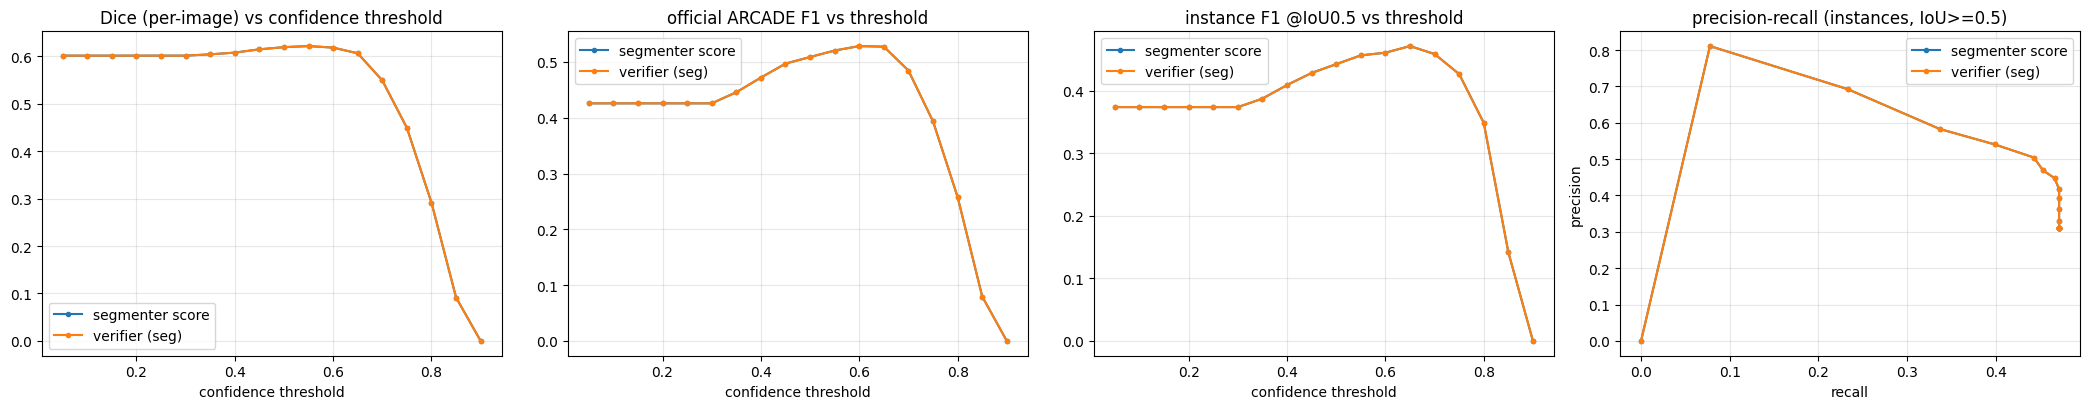

          score  tau  Dice_img  Dice_pooled  official_F1  inst_F1  precision  recall  lesions_per_img
segmenter score 0.05    0.6009       0.6142       0.4257   0.3741     0.3101  0.4715           1.9567
segmenter score 0.10    0.6009       0.6142       0.4257   0.3741     0.3101  0.4715           1.9567
segmenter score 0.15    0.6009       0.6142       0.4257   0.3741     0.3101  0.4715           1.9567
segmenter score 0.20    0.6009       0.6142       0.4257   0.3741     0.3101  0.4715           1.9567
segmenter score 0.25    0.6009       0.6142       0.4257   0.3741     0.3101  0.4715           1.9567
segmenter score 0.30    0.6009       0.6142       0.4257   0.3741     0.3101  0.4715           1.9567
segmenter score 0.35    0.6036       0.6169       0.4456   0.3876     0.3291  0.4715           1.8433
segmenter score 0.40    0.6072       0.6203       0.4718   0.4094     0.3618  0.4715           1.6767
segmenter score 0.45    0.6141       0.6271       0.4969   0.4287     0.3931  0.47

In [20]:
# ---- Dice / F1 vs confidence threshold (descriptive TEST curve, nothing is selected from it) ----
TAUS = np.round(np.linspace(0.05, 0.90, 18), 3); curve = []
for nm, Cc in [("segmenter score", C_TEST), (f"verifier ({BEST_MODE})", C_TEST_VER)]:
    for t in TAUS:
        preds = [select_insts(c, dict(tau=float(t), rel=0.0, max_k=99, top1=False)) for c in Cc]; fm = full_metrics(preds, TEST_ITEMS)
        curve.append(dict(score=nm, tau=float(t), Dice_img=fm["Dice_img"], Dice_pooled=fm["Dice"], official_F1=fm["P1"], inst_F1=fm["F1"], precision=fm["Precision"], recall=fm["Recall"], lesions_per_img=fm["pred_per_img"]))
CURVE = pd.DataFrame(curve)
fig, ax = plt.subplots(1, 4, figsize=(21, 4.2))
for nm, g in CURVE.groupby("score"):
    ax[0].plot(g.tau, g.Dice_img, "-o", ms=3, label=nm); ax[1].plot(g.tau, g.official_F1, "-o", ms=3, label=nm)
    ax[2].plot(g.tau, g.inst_F1, "-o", ms=3, label=nm); ax[3].plot(g.recall, g.precision, "-o", ms=3, label=nm)
for a, t in zip(ax, ["Dice (per-image) vs confidence threshold", "official ARCADE F1 vs threshold", "instance F1 @IoU0.5 vs threshold", "precision-recall (instances, IoU>=0.5)"]): a.set_title(t); a.grid(alpha=.3); a.legend()
ax[0].set_xlabel("confidence threshold"); ax[1].set_xlabel("confidence threshold"); ax[2].set_xlabel("confidence threshold"); ax[3].set_xlabel("recall"); ax[3].set_ylabel("precision")
plt.tight_layout(); print("=== SS-V6: how Dice and F1 move with the confidence threshold (test; descriptive only) ==="); plt.show()
print(CURVE.round(4).to_string(index=False))

In [21]:
# ---- CLAIM GATE ----
print("=== SS-V7: CLAIM GATE (test set, headline operating point; supervisor targets Dice 0.65+, F1 0.55+) ===")
g = []
for nm, m in METHODS.items():
    fm = m["run"][HEADLINE]["fm"]
    g.append({"method": nm, "Dice/img": round(fm["Dice_img"], 4), ">=.65": "YES" if fm["Dice_img"] >= .65 else "no", "Dice pooled": round(fm["Dice"], 4), ">=.65 ": "YES" if fm["Dice"] >= .65 else "no",
              "official F1": round(fm["P1"], 4), ">=.55": "YES" if fm["P1"] >= .55 else "no", "mAP50": round(m["map50"], 4)})
GATE = pd.DataFrame(g); print(GATE.to_string(index=False))
d_f1 = TAB_T3[(TAB_T3.metric == "official F1")].iloc[0]; d_m = TAB_T3[(TAB_T3.metric == "mAP50")].iloc[0]; d_d = TAB_T3[(TAB_T3.metric == "Dice/img")].iloc[0]
print("\n--- what the data supports about the verifier (vs the clean ablation M2) ---")
if BEST_MODE == "seg": print("The verifier was NOT selected on out-of-fold data (segmenter score ranked best). Do not claim a verifier contribution.")
else:
    print(f"mAP50 change {d_m['difference']:+.4f} {d_m['95% CI of difference']} ({'significant' if d_m['CI excludes 0']=='YES' else 'NOT significant'}) | official F1 change {d_f1['difference']:+.4f} {d_f1['95% CI of difference']} ({'significant' if d_f1['CI excludes 0']=='YES' else 'NOT significant'}) | Dice/img change {d_d['difference']:+.4f} {d_d['95% CI of difference']}")
    sig = [x for x in (d_m, d_f1) if x["CI excludes 0"] == "YES" and x["difference"] > 0]
    if sig: print("You MAY claim: a second-stage verifier improves", " and ".join("mAP50" if x is d_m else "official F1" for x in sig), "(paired bootstrap, 95% CI excludes 0). Say it is an adaptation of mask-quality scoring, not a new idea in general.")
    else: print("No metric shows a gain whose CI excludes 0 -> report the verifier as 'tried, no reliable gain'. Do NOT claim an improvement.")
print("\nCompare with the earlier segmenter-only result (Dice/img 0.62, official F1 0.52-0.54, mAP50 0.31-0.34) before writing any 'new best' sentence.")

=== SS-V7: CLAIM GATE (test set, headline operating point; supervisor targets Dice 0.65+, F1 0.55+) ===
                                         method  Dice/img >=.65  Dice pooled >=.65   official F1 >=.55  mAP50
M1 segmenter only (earlier pipeline, full grid)    0.6267    no       0.6365     no       0.5276    no 0.3249
            M2 segmenter only (same candidates)    0.6249    no       0.6345     no       0.5282    no 0.3249
                  M3 segmenter + verifier (seg)    0.6249    no       0.6345     no       0.5282    no 0.3249

--- what the data supports about the verifier (vs the clean ablation M2) ---
The verifier was NOT selected on out-of-fold data (segmenter score ranked best). Do not claim a verifier contribution.

Compare with the earlier segmenter-only result (Dice/img 0.62, official F1 0.52-0.54, mAP50 0.31-0.34) before writing any 'new best' sentence.


=== SS-V8: 3 images where the verifier hurts most (top) and 3 where it helps most (bottom) ===


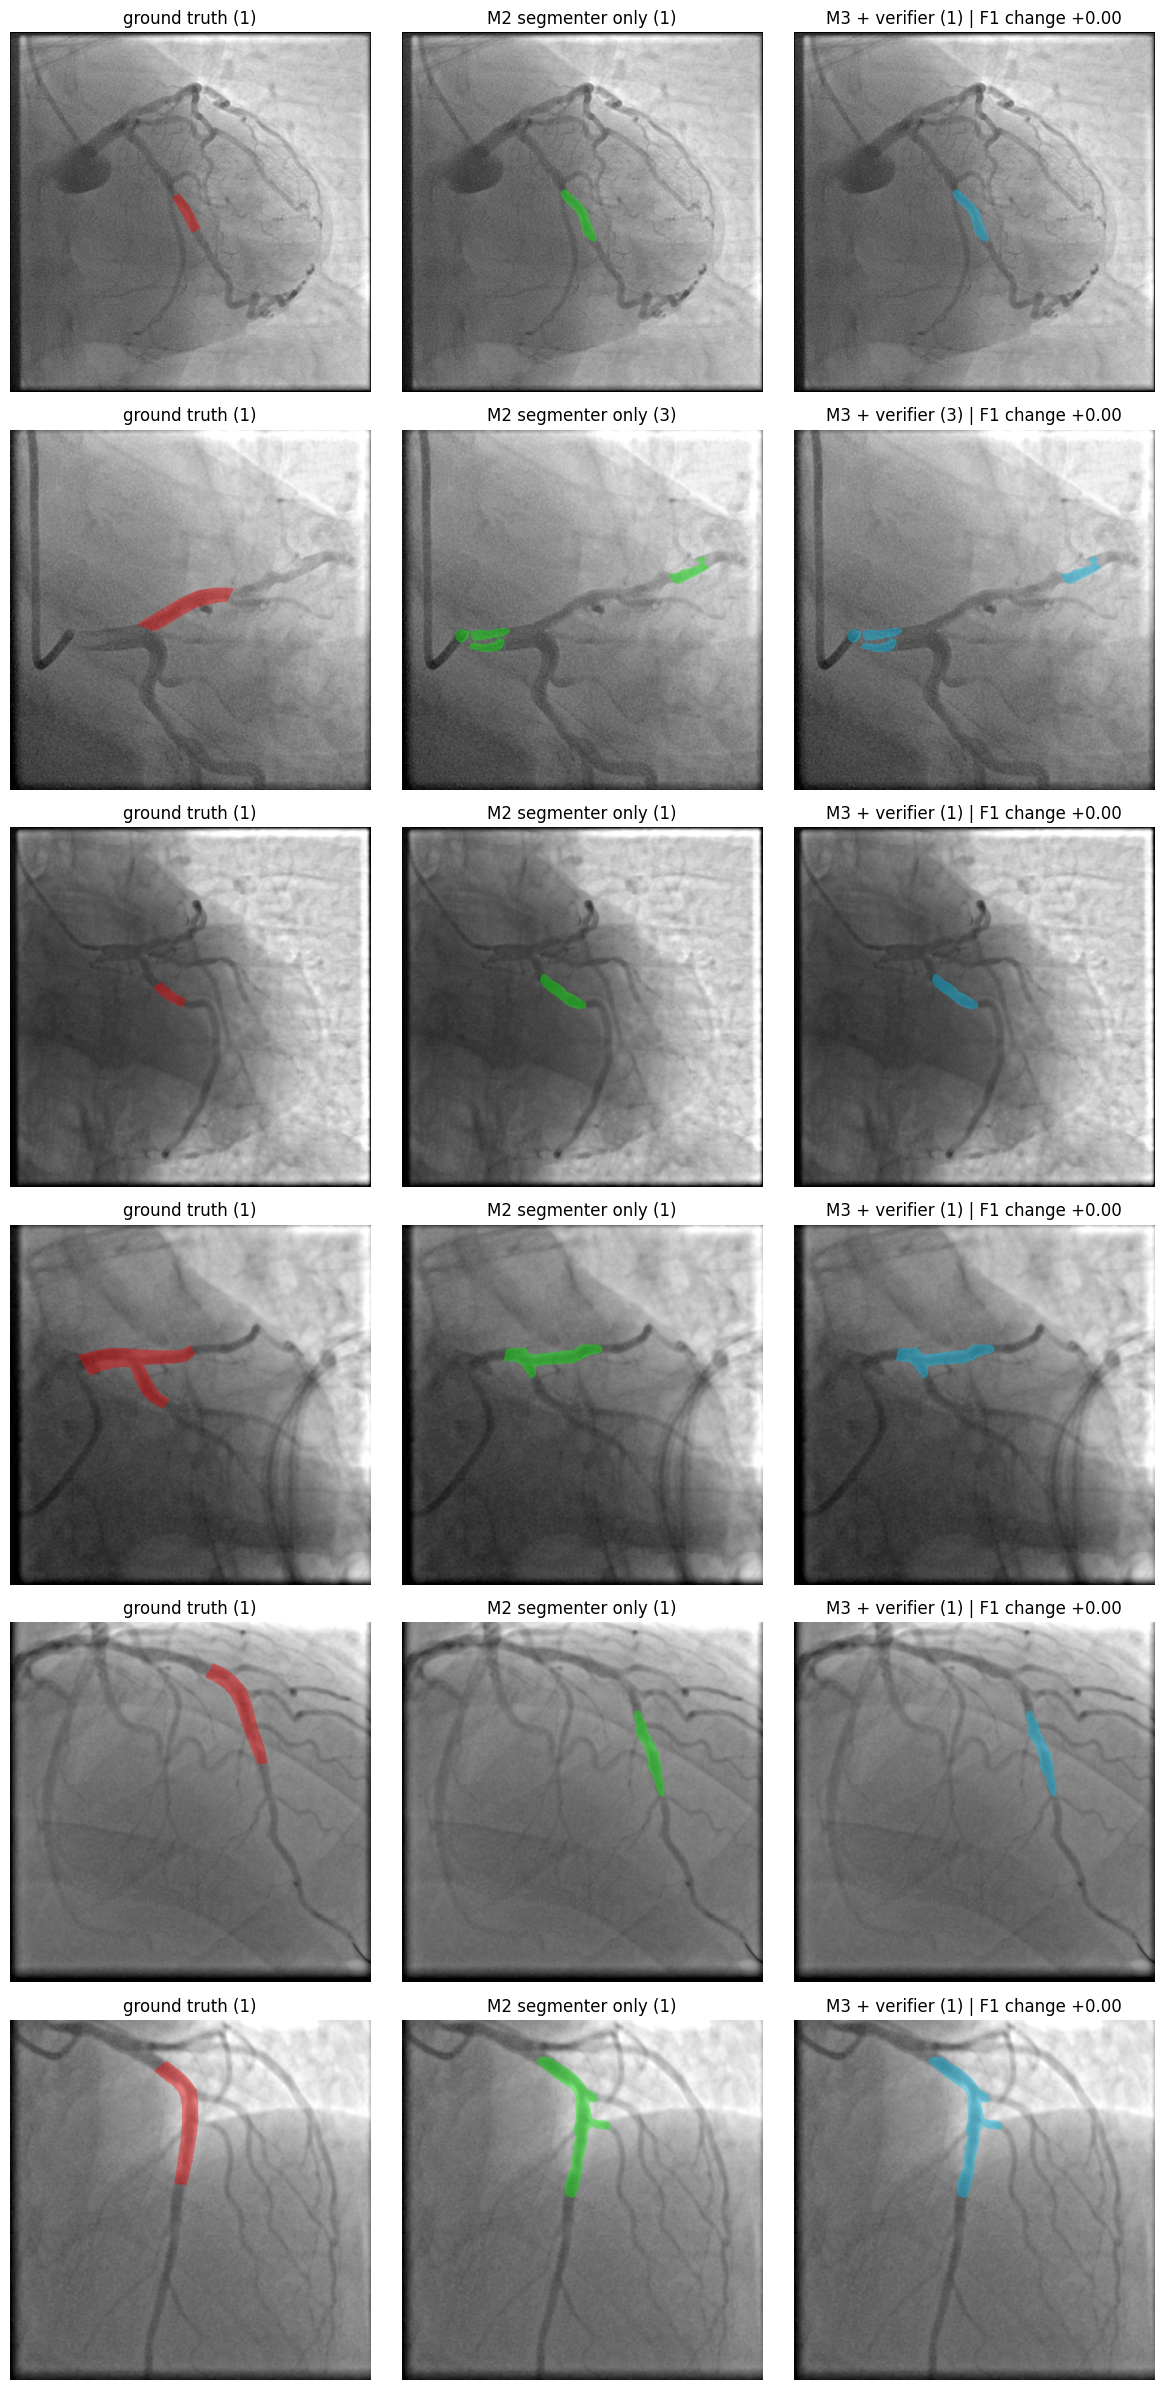

In [22]:
# ---- where does the verifier help / hurt? 3 best and 3 worst test images by change in official F1 (honest: both are shown) ----
d = per_img(M3, "per_image_P1") - per_img(M2, "per_image_P1"); order = np.argsort(d); pick = list(order[:3]) + list(order[-3:])
fig, ax = plt.subplots(len(pick), 3, figsize=(12, 4.0 * len(pick)))
for r_, i in enumerate(pick):
    img = cv2.cvtColor(TEST_IMGS[i], cv2.COLOR_GRAY2RGB)
    for c_, (ttl, preds, col) in enumerate([("ground truth", TEST_ITEMS[i]["gts"], [255, 0, 0]), ("M2 segmenter only", M2["run"][HEADLINE]["preds"][i], [0, 255, 0]), ("M3 + verifier", M3["run"][HEADLINE]["preds"][i], [0, 200, 255])]):
        o = img.copy(); o[paint(preds, TEST_ITEMS[i]["shape"])] = col; ax[r_, c_].imshow(cv2.addWeighted(img, 0.6, o, 0.4, 0)); ax[r_, c_].axis("off")
        ax[r_, c_].set_title(f"{ttl} ({len(preds)})" + (f" | F1 change {d[i]:+.2f}" if c_ == 2 else ""))
plt.tight_layout(); print("=== SS-V8: 3 images where the verifier hurts most (top) and 3 where it helps most (bottom) ==="); plt.show()

In [23]:
TAB_T1.to_csv(OUT_DIR / "test_all_methods.csv", index=False); TAB_T3.to_csv(OUT_DIR / "paired_bootstrap_gain.csv", index=False)
CURVE.to_csv(OUT_DIR / "threshold_curve.csv", index=False); TAB_MODES.to_csv(OUT_DIR / "oof_scoring_modes.csv", index=False); GATE.to_csv(OUT_DIR / "claim_gate_v2.csv", index=False)
pd.DataFrame([{"method": nm, **m["run"][HEADLINE]["pc"]} for nm, m in METHODS.items()]).to_csv(OUT_DIR / "pixel_confusion.csv", index=False)
ZIP_BASE = str(BASE / "results_arcade_dl3_verifier"); shutil.make_archive(ZIP_BASE, "zip", OUT_DIR)
print("Saved to", OUT_DIR, "and", ZIP_BASE + ".zip")
try:
    from google.colab import files; files.download(ZIP_BASE + ".zip")
except Exception: print("(Not on Colab) take results_arcade_dl3_verifier.zip from the notebook's Output panel.")
if SMOKE_TEST: print("\nSMOKE TEST finished: the pipeline runs end-to-end. These numbers mean nothing (1 epoch, ~120 images). Set SMOKE_TEST = False and run again.")

Saved to /content/outputs and /content/results_arcade_dl3_verifier.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## How to write this up (read before the thesis)
* **Definitions, always:** *Dice* = mean per-image Dice of the final predicted masks (pooled/global Dice and the pixel TP/FP/FN/TN table are also given); *official F1* = ARCADE-style mean F1 (per-image, greedy Dice matching, our implementation); *mAP* = COCO-style mask AP over the ranked candidate list.
* **Instance segmentation framing (your supervisor's advice):** the main goal is mAP and F1; Dice depends on the confidence threshold, which is why SS-V6 shows Dice/F1 across thresholds.
* **The verifier is a contribution only if SS-V5 says so** (paired CI of the gain excludes 0). If it does, write: *"a cross-validated second-stage lesion verifier (ResNet18 on image + probability map + candidate mask) that re-scores segmentation candidates"*, cite Mask Scoring R-CNN for the quality-scoring idea, and show M1/M2/M3 as the ablation. If it does not, the honest sentence is "a verifier was tried and gave no reliable gain".
* **Limitations to state:** one dataset, one test split (300 images), verifier trained on out-of-fold probabilities of single models while test candidates come from the 5-model average (mild mismatch), the official-F1 code is a re-implementation, targets (Dice 0.65 / F1 0.55) reached only if SS-V7 says YES.